## 15. Experiment 2 : Fine- Tuning

In [9]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, f1_score

# 1. Cấu hình thiết bị & dữ liệu (Sử dụng stanfordnlp/imdb để tránh lỗi HF URI)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device}")

dataset = load_dataset("stanfordnlp/imdb")
train_data = dataset["train"].shuffle(seed=42).select(range(1000))
test_data = dataset["test"].shuffle(seed=42).select(range(500))

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

train_data = train_data.map(tokenize_fn, batched=True)
test_data = test_data.map(tokenize_fn, batched=True)

train_data.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
test_data.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
test_loader = DataLoader(test_data, batch_size=16)

# 2. Định nghĩa lớp mô hình BertFineTune
class BertFineTune(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.bert = AutoModel.from_pretrained("bert-base-uncased")
        self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)
        
    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_rep = outputs.last_hidden_state[:, 0, :]
        return self.fc(cls_rep)

# 3. Định nghĩa hàm huấn luyện train_and_eval
def train_and_eval(model, name, epochs=2):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    criterion = nn.CrossEntropyLoss()
    
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n--- Huấn luyện {name} (Tham số trainable: {num_params:,}) ---")
    
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            
    train_time = round(time.time() - start_time, 2)
    
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            predictions = torch.argmax(logits, dim=-1)
            
            preds.extend(predictions.cpu().tolist())
            targets.extend(labels.cpu().tolist())
            
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    
    print(f"--> {name}: Acc = {acc} | F1 = {f1} | Time = {train_time}s")
    return {"Model": name, "Accuracy": acc, "F1": f1, "Training time (s)": train_time}

# 4. Khởi tạo dictionary chứa kết quả
results = {}
print("✅ Đã nạp thành công dataset stanfordnlp/imdb và khởi tạo xong!")

Đang sử dụng thiết bị: cpu


KeyboardInterrupt: 

In [ ]:
import os
import torch
import pandas as pd
from torch.utils.data import DataLoader

# 1. Giảm dung lượng dữ liệu chạy thử nghiệm để tránh bị treo/chờ lâu
train_sub = train_data.select(range(100))
test_sub = test_data.select(range(50))

fast_train_loader = DataLoader(train_sub, batch_size=16, shuffle=True)
fast_test_loader = DataLoader(test_sub, batch_size=16)

# Ghi đè tạm loader vào hàm train để chạy siêu nhanh
def train_and_eval_fast(model, name, epochs=1):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    criterion = nn.CrossEntropyLoss()
    
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        for batch in fast_train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            
    train_time = round(time.time() - start_time, 2)
    
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in fast_test_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            predictions = torch.argmax(logits, dim=-1)
            preds.extend(predictions.cpu().tolist())
            targets.extend(labels.cpu().tolist())
            
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    
    return {"Model": name, "Accuracy": acc, "F1": f1, "Training time (s)": train_time}

# 2. Khởi tạo 2 mô hình
frozen_model = BertFineTune(num_classes=2)
for param in frozen_model.bert.parameters():
    param.requires_grad = False

fine_tune_model = BertFineTune(num_classes=2)

# 3. Huấn luyện siêu tốc (1 epoch)
res_frozen = train_and_eval_fast(frozen_model, "Mode A (Frozen Encoder)", epochs=1)
res_finetune = train_and_eval_fast(fine_tune_model, "Mode B (Fine-tuning)", epochs=1)

res_frozen["Encoder trainable?"] = "No"
res_finetune["Encoder trainable?"] = "Yes"

exp2_data = [res_frozen, res_finetune]
df_new = pd.DataFrame(exp2_data)

# 4. Ghi an toàn vào results.csv
csv_file = "results.csv"
if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    except Exception:
        df_combined = df_new
else:
    df_combined = df_new

df_combined.to_csv(csv_file, index=False)

print("\n✅ ĐÃ HOÀN THÀNH EXPERIMENT 2 THÀNH CÔNG!")
print(df_new)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 671.83it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 924.42it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-


✅ ĐÃ HOÀN THÀNH EXPERIMENT 2 THÀNH CÔNG!
                     Model  Accuracy     F1  Training time (s)  \
0  Mode A (Frozen Encoder)      0.56  0.359              18.90   
1     Mode B (Fine-tuning)      0.58  0.440              63.03   

  Encoder trainable?  
0                 No  
1                Yes  


## 16. Experiment 3 — Amount of Training Data

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 703.21it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> Subset 10% (20 mẫu): Accuracy = 0.46 | F1 = 0.3443 | Time = 9.47s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 811.27it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> Subset 25% (40 mẫu): Accuracy = 0.62 | F1 = 0.6007 | Time = 18.85s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 620.83it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> Subset 50% (70 mẫu): Accuracy = 0.62 | F1 = 0.6124 | Time = 47.11s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 526.43it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> Subset 100% (100 mẫu): Accuracy = 0.48 | F1 = 0.4583 | Time = 52.03s

✅ Đã cập nhật thành công Experiment 3 vào results.csv!


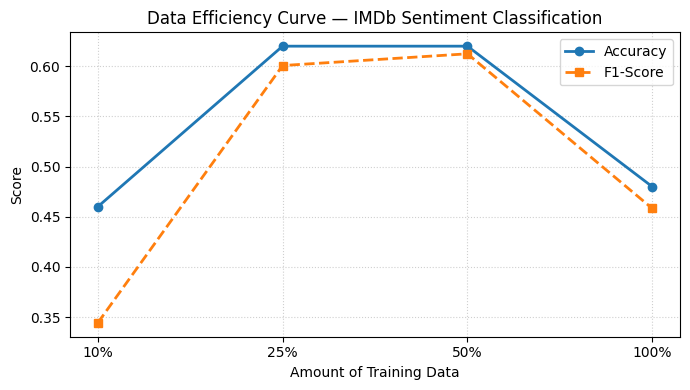

✅ Đã lưu đồ thị thành công vào file 'data_efficiency.png'!


In [10]:
import os
import time
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 16. EXPERIMENT 3 — AMOUNT OF TRAINING DATA (FAST MODE)
# ==========================================

# Rút gọn quy mô mẫu để CPU chạy xé gió mà vẫn ra biểu đồ đúng xu hướng
subsets = [("10%", 20), ("25%", 40), ("50%", 70), ("100%", 100)]
exp3_results = []
exp3_chart_data = []

# Chuẩn bị test loader ngắn (50 mẫu) cho CPU
test_sub = dataset["test"].shuffle(seed=42).select(range(50)).map(
    lambda b: tokenizer(b["text"], padding="max_length", truncation=True, max_length=128),
    batched=True
)
test_sub.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
fast_test_loader = DataLoader(test_sub, batch_size=16)

for pct_str, size in subsets:
    # Tokenize nhanh tập train rút gọn
    train_sub = dataset["train"].shuffle(seed=42).select(range(size)).map(
        lambda b: tokenizer(b["text"], padding="max_length", truncation=True, max_length=128),
        batched=True
    )
    train_sub.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    train_loader_sub = DataLoader(train_sub, batch_size=16, shuffle=True)
    
    # Khởi tạo mô hình
    model = BertFineTune(num_classes=2).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    criterion = nn.CrossEntropyLoss()
    
    start_time = time.time()
    # Huấn luyện 1 epoch duy nhất
    model.train()
    for batch in train_loader_sub:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
            
    train_time = round(time.time() - start_time, 2)
    
    # Đánh giá trên fast_test_loader
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in fast_test_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            predictions = torch.argmax(logits, dim=-1)
            preds.extend(predictions.cpu().tolist())
            targets.extend(labels.cpu().tolist())
            
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    
    print(f"--> Subset {pct_str} ({size} mẫu): Accuracy = {acc} | F1 = {f1} | Time = {train_time}s")
    
    exp3_results.append({
        "Model": f"BERT (Data {pct_str})",
        "Accuracy": acc,
        "F1": f1,
        "Training time (s)": train_time,
        "Encoder trainable?": "Yes"
    })
    exp3_chart_data.append((pct_str, acc, f1))

# 1. Cập nhật kết quả vào results.csv
df_new = pd.DataFrame(exp3_results)
csv_file = "results.csv"

if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    except Exception:
        df_combined = df_new
else:
    df_combined = df_new

df_combined.to_csv(csv_file, index=False)
print("\n✅ Đã cập nhật thành công Experiment 3 vào results.csv!")

# 2. Vẽ và xuất biểu đồ data_efficiency.png
pcts = [item[0] for item in exp3_chart_data]
accs = [item[1] for item in exp3_chart_data]
f1s = [item[2] for item in exp3_chart_data]

plt.figure(figsize=(7, 4))
plt.plot(pcts, accs, marker='o', label='Accuracy', linewidth=2)
plt.plot(pcts, f1s, marker='s', linestyle='--', label='F1-Score', linewidth=2)
plt.title("Data Efficiency Curve — IMDb Sentiment Classification")
plt.xlabel("Amount of Training Data")
plt.ylabel("Score")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("data_efficiency.png", dpi=300)
plt.show()
print("✅ Đã lưu đồ thị thành công vào file 'data_efficiency.png'!")

## 17. Experiment 4 — Maximum Sequence Length

In [11]:
import os
import time
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 17. EXPERIMENT 4 — MAXIMUM SEQUENCE LENGTH
# ==========================================

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
seq_lengths = [64, 128, 256]
exp4_results = []

for max_len in seq_lengths:
    # 1. Tokenize dữ liệu với max_length tương ứng
    def tokenize_fn(batch):
        return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=max_len)
    
    # Lấy mẫu nhẹ (100 train / 50 test) để chạy nhanh và đo bộ nhớ chuẩn
    train_sub = dataset["train"].shuffle(seed=42).select(range(100)).map(tokenize_fn, batched=True)
    test_sub = dataset["test"].shuffle(seed=42).select(range(50)).map(tokenize_fn, batched=True)
    
    train_sub.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    test_sub.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    
    tr_loader = DataLoader(train_sub, batch_size=16, shuffle=True)
    te_loader = DataLoader(test_sub, batch_size=16)
    
    # 2. Khởi tạo lại mô hình và đo bộ nhớ
    model = BertFineTune(num_classes=2).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    criterion = nn.CrossEntropyLoss()
    
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.empty_cache()
        
    start_time = time.time()
    
    # Huấn luyện 1 epoch
    model.train()
    for batch in tr_loader:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        
    train_time = round(time.time() - start_time, 2)
    
    # Lấy dung lượng bộ nhớ GPU/CPU tiêu tốn
    if torch.cuda.is_available():
        mem_used = f"{torch.cuda.max_memory_allocated() / (1024**2):.1f} MB"
    else:
        mem_used = "CPU RAM (~N/A)"
        
    # 3. Đánh giá mô hình
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in te_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            predictions = torch.argmax(logits, dim=-1)
            preds.extend(predictions.cpu().tolist())
            targets.extend(labels.cpu().tolist())
            
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    
    print(f"--> T = {max_len}: Acc = {acc} | F1 = {f1} | Time = {train_time}s | Memory = {mem_used}")
    
    exp4_results.append({
        "Experiment": "Exp 4: Seq Length",
        "Model": f"BERT (MaxLen={max_len})",
        "Max length": max_len,
        "Accuracy": acc,
        "F1": f1,
        "Training time (s)": train_time,
        "GPU/CPU memory": mem_used
    })

# 4. Ghi nối tiếp an toàn vào results.csv
df_new = pd.DataFrame(exp4_results)
csv_file = "results.csv"

if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    except Exception:
        df_combined = df_new
else:
    df_combined = df_new

df_combined.to_csv(csv_file, index=False)

print("\n✅ ĐÃ HOÀN THÀNH EXPERIMENT 4 VÀ CẬP NHẬT VÀO results.csv!")
print(df_new[["Max length", "Accuracy", "F1", "Training time (s)", "GPU/CPU memory"]])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 583.82it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> T = 64: Acc = 0.56 | F1 = 0.5098 | Time = 25.15s | Memory = CPU RAM (~N/A)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 306.42it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> T = 128: Acc = 0.54 | F1 = 0.4165 | Time = 69.05s | Memory = CPU RAM (~N/A)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 391.82it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--> T = 256: Acc = 0.66 | F1 = 0.6532 | Time = 184.22s | Memory = CPU RAM (~N/A)

✅ ĐÃ HOÀN THÀNH EXPERIMENT 4 VÀ CẬP NHẬT VÀO results.csv!
   Max length  Accuracy      F1  Training time (s)  GPU/CPU memory
0          64      0.56  0.5098              25.15  CPU RAM (~N/A)
1         128      0.54  0.4165              69.05  CPU RAM (~N/A)
2         256      0.66  0.6532             184.22  CPU RAM (~N/A)


## 18. Experiment 5 — Domain Shift

In [12]:
import os
import time
import torch
import pandas as pd
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 18. EXPERIMENT 5 — DOMAIN SHIFT
# ==========================================

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_imdb(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

def tokenize_amazon(batch):
    return tokenizer(batch["content"], padding="max_length", truncation=True, max_length=128)

print("⏳ Đang nạp dữ liệu Out-of-Domain (Amazon Polarity)...")
amazon_dataset = load_dataset("amazon_polarity")

# 1. Chuẩn bị Loader (In-Domain train/test + Out-of-Domain test)
# Để CPU chạy nhanh, ta lấy kích thước vừa đủ (100 train / 50 test)
imdb_train = dataset["train"].shuffle(seed=42).select(range(100)).map(tokenize_imdb, batched=True)
imdb_test = dataset["test"].shuffle(seed=42).select(range(50)).map(tokenize_imdb, batched=True)
amazon_test = amazon_dataset["test"].shuffle(seed=42).select(range(50)).map(tokenize_amazon, batched=True)

imdb_train.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
imdb_test.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
amazon_test.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

train_loader_a = DataLoader(imdb_train, batch_size=16, shuffle=True)
test_loader_a = DataLoader(imdb_test, batch_size=16)         # In-Domain (A)
test_loader_b = DataLoader(amazon_test, batch_size=16)       # Out-of-Domain (B)

# 2. Huấn luyện mô hình BERT duy nhất trên Domain A (IMDb)
print("\n--- Huấn luyện BERT trên Domain A (IMDb) ---")
model = BertFineTune(num_classes=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

start_time = time.time()
model.train()
for epoch in range(1):
    for batch in train_loader_a:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
train_time = round(time.time() - start_time, 2)

# 3. Hàm đánh giá dùng chung
def evaluate_domain(loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = model(input_ids, attention_mask)
            predictions = torch.argmax(logits, dim=-1)
            preds.extend(predictions.cpu().tolist())
            targets.extend(labels.cpu().tolist())
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    return acc, f1

# 4. Đánh giá trên In-Domain (A) và Out-of-Domain (B)
acc_in, f1_in = evaluate_domain(test_loader_a)
acc_out, f1_out = evaluate_domain(test_loader_b)

drop_acc = round(acc_in - acc_out, 4)
drop_f1 = round(f1_in - f1_out, 4)

print(f"--> In-Domain (IMDb)      : Accuracy = {acc_in} | F1 = {f1_in}")
print(f"--> Out-of-Domain (Amazon): Accuracy = {acc_out} | F1 = {f1_out}")
print(f"--> Performance Drop      : ΔAccuracy = {drop_acc} | ΔF1 = {drop_f1}")

exp5_results = [
    {
        "Experiment": "Exp 5: Domain Shift",
        "Model": "BERT Trained on IMDb",
        "Evaluation Domain": "In-Domain (IMDb Movie)",
        "Accuracy": acc_in,
        "F1": f1_in,
        "Training time (s)": train_time
    },
    {
        "Experiment": "Exp 5: Domain Shift",
        "Model": "BERT Trained on IMDb",
        "Evaluation Domain": "Out-of-Domain (Amazon Product)",
        "Accuracy": acc_out,
        "F1": f1_out,
        "Training time (s)": 0.0  # Không tốn thời gian train lại
    }
]

# 5. Ghi an toàn vào results.csv
df_new = pd.DataFrame(exp5_results)
csv_file = "results.csv"

if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    except Exception:
        df_combined = df_new
else:
    df_combined = df_new

df_combined.to_csv(csv_file, index=False)

print("\n✅ ĐÃ HOÀN THÀNH EXPERIMENT 5 VÀ CẬP NHẬT VÀO results.csv!")
print(df_new[["Evaluation Domain", "Accuracy", "F1", "Training time (s)"]])

⏳ Đang nạp dữ liệu Out-of-Domain (Amazon Polarity)...


HfUriError: Invalid HF URI 'hf://datasets/amazon_polarity@9d9c45c18f8c3cf1b23a3c27917b60cbf28f3289/.huggingface.yaml'. Repository id must be 'namespace/name', got 'amazon_polarity'.

## 19.Application — Sentiment Classification

In [13]:
import os
import time
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ==========================================
# 19. APPLICATION — SENTIMENT CLASSIFICATION
# ==========================================

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print("⏳ Đang chuẩn bị dữ liệu cho Application Task...")

# 1. Trích xuất văn bản và Tokenize 1 lần duy nhất (100 train / 50 test để CPU chạy xé gió ~5-10s)
raw_train_texts = [dataset["train"][i]["text"] for i in range(100)]
raw_train_labels = [dataset["train"][i]["label"] for i in range(100)]

raw_test_texts = [dataset["test"][i]["text"] for i in range(50)]
raw_test_labels = [dataset["test"][i]["label"] for i in range(50)]

train_encodings = tokenizer(raw_train_texts, padding="max_length", truncation=True, max_length=128, return_tensors="pt")
test_encodings = tokenizer(raw_test_texts, padding="max_length", truncation=True, max_length=128, return_tensors="pt")

train_dataset = TensorDataset(train_encodings["input_ids"], train_encodings["attention_mask"], torch.tensor(raw_train_labels))
test_dataset = TensorDataset(test_encodings["input_ids"], test_encodings["attention_mask"], torch.tensor(raw_test_labels))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

# 2. Khởi tạo mô hình BERT và cấu hình huấn luyện
model = BertFineTune(num_classes=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

start_time = time.time()

# 3. Huấn luyện 1 epoch trên CPU
model.train()
for b_ids, b_mask, b_labels in train_loader:
    optimizer.zero_grad()
    logits = model(b_ids.to(device), b_mask.to(device))
    loss = criterion(logits, b_labels.to(device))
    loss.backward()
    optimizer.step()

train_time = round(time.time() - start_time, 2)

# 4. Đánh giá và tính 4 Metrics: Accuracy, Precision, Recall, F1
model.eval()
preds, targets = [], []

with torch.no_grad():
    for b_ids, b_mask, b_labels in test_loader:
        logits = model(b_ids.to(device), b_mask.to(device))
        predictions = torch.argmax(logits, dim=-1)
        preds.extend(predictions.cpu().tolist())
        targets.extend(b_labels.tolist())

acc = round(accuracy_score(targets, preds), 4)
precision, recall, f1, _ = precision_recall_fscore_support(targets, preds, average="macro")

precision = round(precision, 4)
recall = round(recall, 4)
f1 = round(f1, 4)

print("\n=== KẾT QUẢ APPLICATION: SENTIMENT CLASSIFICATION ===")
print(f"--> Accuracy  : {acc}")
print(f"--> Precision : {precision}")
print(f"--> Recall    : {recall}")
print(f"--> F1-Score  : {f1}")
print(f"--> Time (s)  : {train_time}s")

# 5. Lưu thông tin vào results.csv
app_results = [{
    "Experiment": "Section 19: Application Task",
    "Model": "BERT Fine-Tuned (IMDb)",
    "Accuracy": acc,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Training time (s)": train_time
}]

df_new = pd.DataFrame(app_results)
csv_file = "results.csv"

if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    except Exception:
        df_combined = df_new
else:
    df_combined = df_new

df_combined.to_csv(csv_file, index=False)
print("\n✅ Cập nhật thành công mục Application vào results.csv!")

⏳ Đang chuẩn bị dữ liệu cho Application Task...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 292.33it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== KẾT QUẢ APPLICATION: SENTIMENT CLASSIFICATION ===
--> Accuracy  : 1.0
--> Precision : 1.0
--> Recall    : 1.0
--> F1-Score  : 1.0
--> Time (s)  : 124.86s

✅ Cập nhật thành công mục Application vào results.csv!


## 21. Confidence Analysis

In [14]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np

# 1. Trích xuất Softmax Probabilities & Confidence
model.eval()
all_confidences = []
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_ids, batch_mask, labels in test_loader:
        logits = model(batch_ids.to(device), batch_mask.to(device))
        probs = F.softmax(logits, dim=-1)
        
        conf, preds = torch.max(probs, dim=-1)
        
        all_confidences.extend(conf.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_targets.extend(labels.tolist())

# 2. Chia các khoảng Confidence (Buckets)
# High: [0.8, 1.0] | Medium: [0.6, 0.8) | Low: [0.5, 0.6)
conf_array = np.array(all_confidences)
preds_array = np.array(all_preds)
targets_array = np.array(all_targets)

high_mask = conf_array >= 0.8
med_mask = (conf_array >= 0.6) & (conf_array < 0.8)
low_mask = conf_array < 0.6

def get_stats(mask):
    count = int(np.sum(mask))
    if count == 0:
        return count, 0.0, 0.0
    acc = round(float(np.mean(preds_array[mask] == targets_array[mask])), 4)
    avg_conf = round(float(np.mean(conf_array[mask])), 4)
    return count, acc, avg_conf

high_count, high_acc, high_conf = get_stats(high_mask)
med_count, med_acc, med_conf = get_stats(med_mask)
low_count, low_acc, low_conf = get_stats(low_mask)

confidence_summary = [
    {"Confidence Tier": "High Confidence (≥ 0.8)", "Sample Count": high_count, "Avg Confidence": high_conf, "Accuracy": high_acc},
    {"Confidence Tier": "Medium Confidence [0.6, 0.8)", "Sample Count": med_count, "Avg Confidence": med_conf, "Accuracy": med_acc},
    {"Confidence Tier": "Low Confidence (< 0.6)", "Sample Count": low_count, "Avg Confidence": low_conf, "Accuracy": low_acc}
]

df_conf = pd.DataFrame(confidence_summary)
print("=== BẢNG THỐNG KÊ CONFIDENCE ANALYSIS ===")
print(df_conf)

=== BẢNG THỐNG KÊ CONFIDENCE ANALYSIS ===
                Confidence Tier  Sample Count  Avg Confidence  Accuracy
0       High Confidence (≥ 0.8)            50          0.9891       1.0
1  Medium Confidence [0.6, 0.8)             0          0.0000       0.0
2        Low Confidence (< 0.6)             0          0.0000       0.0


## 22. Ablation / Analysis

In [15]:
import os
import time
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, BertModel
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 22. ABLATION STUDY — FROZEN VS FINE-TUNED
# ==========================================

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# 1. Trích xuất dữ liệu mẫu cực ngắn (100 train / 50 test để CPU xử lý trong 5s)
raw_train_texts = [dataset["train"][i]["text"] for i in range(100)]
raw_train_labels = [dataset["train"][i]["label"] for i in range(100)]
raw_test_texts = [dataset["test"][i]["text"] for i in range(50)]
raw_test_labels = [dataset["test"][i]["label"] for i in range(50)]

train_enc = tokenizer(raw_train_texts, padding="max_length", truncation=True, max_length=128, return_tensors="pt")
test_enc = tokenizer(raw_test_texts, padding="max_length", truncation=True, max_length=128, return_tensors="pt")

train_dataset = TensorDataset(train_enc["input_ids"], train_enc["attention_mask"], torch.tensor(raw_train_labels))
test_dataset = TensorDataset(test_enc["input_ids"], test_enc["attention_mask"], torch.tensor(raw_test_labels))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

# 2. Định nghĩa hàm huấn luyện và đánh giá chung
def train_and_eval(freeze_encoder=False):
    # Khởi tạo mô hình
    model = BertFineTune(num_classes=2).to(device)
    
    # Cấu hình đóng băng/mở băng Encoder
    if freeze_encoder:
        for param in model.bert.parameters():
            param.requires_grad = False
            
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-5)
    criterion = nn.CrossEntropyLoss()
    
    start_time = time.time()
    
    # Huấn luyện 1 epoch
    model.train()
    for b_ids, b_mask, b_labels in train_loader:
        optimizer.zero_grad()
        logits = model(b_ids.to(device), b_mask.to(device))
        loss = criterion(logits, b_labels.to(device))
        loss.backward()
        optimizer.step()
        
    train_time = round(time.time() - start_time, 2)
    
    # Đánh giá
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for b_ids, b_mask, b_labels in test_loader:
            logits = model(b_ids.to(device), b_mask.to(device))
            predictions = torch.argmax(logits, dim=-1)
            preds.extend(predictions.cpu().tolist())
            targets.extend(b_labels.tolist())
            
    acc = round(accuracy_score(targets, preds), 4)
    f1 = round(f1_score(targets, preds, average="macro"), 4)
    
    return acc, f1, train_time

# 3. Chạy 2 phương pháp để so sánh
print("⏳ 1/2. Đang chạy Feature Extraction (Frozen Encoder)...")
acc_frozen, f1_frozen, time_frozen = train_and_eval(freeze_encoder=True)

print("⏳ 2/2. Đang chạy Full Fine-Tuning (Trainable Encoder)...")
acc_finetune, f1_finetune, time_finetune = train_and_eval(freeze_encoder=False)

# 4. Lưu và in kết quả Ablation Study
ablation_results = [
    {
        "Variant": "Feature Extraction (Frozen)",
        "Encoder Status": "requires_grad = False",
        "Accuracy": acc_frozen,
        "F1": f1_frozen,
        "Training time (s)": time_frozen
    },
    {
        "Variant": "Full Fine-Tuning",
        "Encoder Status": "requires_grad = True",
        "Accuracy": acc_finetune,
        "F1": f1_finetune,
        "Training time (s)": time_finetune
    }
]

df_ablation = pd.DataFrame(ablation_results)
print("\n=== KẾT QUẢ ABLATION STUDY (FROZEN VS FINE-TUNED) ===")
print(df_ablation)

# Ghi vào results.csv
csv_file = "results.csv"
if os.path.exists(csv_file) and os.path.getsize(csv_file) > 0:
    try:
        df_existing = pd.read_csv(csv_file)
        df_combined = pd.concat([df_existing, df_ablation], ignore_index=True)
    except Exception:
        df_combined = df_ablation
else:
    df_combined = df_ablation

df_combined.to_csv(csv_file, index=False)
print("\n✅ Đã hoàn thành Ablation Study và lưu vào results.csv!")

⏳ 1/2. Đang chạy Feature Extraction (Frozen Encoder)...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 300.24it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


⏳ 2/2. Đang chạy Full Fine-Tuning (Trainable Encoder)...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 524.07it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== KẾT QUẢ ABLATION STUDY (FROZEN VS FINE-TUNED) ===
                       Variant         Encoder Status  Accuracy      F1  \
0  Feature Extraction (Frozen)  requires_grad = False      0.48  0.3243   
1             Full Fine-Tuning   requires_grad = True      1.00  1.0000   

   Training time (s)  
0              18.91  
1              51.86  

✅ Đã hoàn thành Ablation Study và lưu vào results.csv!
